In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from numba import njit, prange

In [2]:
# -------------------------
# grid (quadrante 0 ≤ x, y ≤ L)
# -------------------------

L  = 40.0
dx = 0.05
N  = int(round(L/dx)) + 1
x  = dx*np.arange(N)

dt    = 0.02
T     = 60.0
nsave = 5

RMAX = 13.0
h    = 0.01
r    = h*np.arange(int(round(RMAX/h)) + 1)

# -------------------------
# parâmetros
# -------------------------

D = 2
s = 0.5

A  = np.cosh(2*s)/np.sinh(2*s)
g2 = -3.0*A
g3 = 2.0

In [3]:
# -------------------------
# perfil estático e modos
# -------------------------

trapz = getattr(np, "trapezoid", None) or np.trapz

def rk4_radial(f, y0, y1, h, n, para=False):
    y = np.zeros((n, 2))
    y[0], y[1] = y0, y1
    for i in range(1, n - 1):
        k1 = f(i*h, y[i])
        k2 = f((i + 0.5)*h, y[i] + 0.5*h*k1)
        k3 = f((i + 0.5)*h, y[i] + 0.5*h*k2)
        k4 = f((i + 1)*h, y[i] + h*k3)
        y[i+1] = y[i] + h/6*(k1 + 2*k2 + 2*k3 + k4)
        if para and (y[i+1, 0] < 0 or y[i+1, 1] > 0):
            return y[:i+2]
    return y

def Vp(p):
    return p*(1 + g2*p + g3*p**2)

def perfil(p0, hp=2e-3):
    f = lambda rv, y: np.array([y[1], Vp(y[0]) - (D - 1)/rv*y[1]])
    return rk4_radial(f, [p0, 0.0], [p0 + Vp(p0)*hp**2/(2*D), Vp(p0)*hp/D],
                      hp, int(round(RMAX/hp)) + 1, para=True), hp

lo = A - np.sqrt(A**2 - 1)
hi = (3*A + np.sqrt(9*A**2 - 8))/4
for _ in range(100):
    mid = 0.5*(lo + hi)
    y, hp = perfil(mid)
    if y[-1, 0] < 0:
        hi = mid
    elif y[-1, 1] > 0:
        lo = mid
    else:
        break

y, hp = perfil(lo)
pp   = y[:-1, 0]
rp   = hp*np.arange(len(pp))
phiS = np.interp(r, rp, pp, right=0.0)

def U(p):
    return 1 - 6*A*p + 6*p**2

def eta_tiro(w2, l):
    f = lambda rv, y: np.array([y[1], -(D - 1)/rv*y[1]
                                + (l*(l + D - 2)/rv**2 + U(np.interp(rv, rp, pp, right=0.0)) - w2)*y[0]])
    if l == 0:
        c = (U(phiS[0]) - w2)/D
        return rk4_radial(f, [1.0, 0.0], [1 + 0.5*c*h**2, c*h], h, len(r))[:, 0]
    return rk4_radial(f, [0.0, 0.0], [h**l, l*h**(l - 1)], h, len(r))[:, 0]

def autovalor(l, w2min, w2max, n=25):
    F  = lambda w2: eta_tiro(w2, l)[-1]
    ws = np.linspace(w2min, w2max, n)
    Fs = np.array([F(w) for w in ws])
    k  = np.where(np.sign(Fs[:-1]) != np.sign(Fs[1:]))[0][0]
    return brentq(F, ws[k], ws[k + 1], xtol=1e-12)

def autofuncao(w2, l):
    eta = eta_tiro(w2, l)
    return eta/np.sqrt(trapz(r**(D - 1)*eta**2, r))

w2_00 = autovalor(0, -1.5, 0.0)
w2_02 = autovalor(2, 0.0, 1.0)
w_02  = np.sqrt(w2_02)

eta00 = autofuncao(w2_00, 0)
eta02 = autofuncao(w2_02, 2)

In [4]:
# -------------------------
# equações
# -------------------------

@njit(parallel=True, fastmath=True, cache=True)
def eqs(phi, acc, dx, g2, g3):
    N  = phi.shape[0]
    c4 = 1.0/(12*dx**2)
    c2 = 1.0/dx**2
    c1 = 1.0/(12*dx)
    for i in prange(N - 1):
        for j in range(N - 1):
            f = phi[i, j]
            if i < N - 2:
                fxx = (-phi[i+2, j] + 16*phi[i+1, j] - 30*f + 16*phi[abs(i-1), j] - phi[abs(i-2), j])*c4
            else:
                fxx = (phi[i+1, j] - 2*f + phi[i-1, j])*c2
            if j < N - 2:
                fyy = (-phi[i, j+2] + 16*phi[i, j+1] - 30*f + 16*phi[i, abs(j-1)] - phi[i, abs(j-2)])*c4
            else:
                fyy = (phi[i, j+1] - 2*f + phi[i, j-1])*c2
            lap = fxx + fyy
            acc[i, j] = lap - f*(1 + g2*f + g3*f*f)

@njit(cache=True)
def rk4(phi, pi, dx, dt, nt, nsave, g2, g3):
    N  = phi.shape[0]
    a1 = np.zeros((N, N)); a2 = np.zeros((N, N))
    a3 = np.zeros((N, N)); a4 = np.zeros((N, N))
    c1 = np.zeros((nt//nsave + 1, N)); c2 = np.zeros((nt//nsave + 1, N))
    c1[0] = phi[:, 0]; c2[0] = phi[0, :]
    for n in range(1, nt + 1):
        eqs(phi, a1, dx, g2, g3)
        eqs(phi + 0.5*dt*pi, a2, dx, g2, g3)
        eqs(phi + 0.5*dt*pi + 0.25*dt**2*a1, a3, dx, g2, g3)
        eqs(phi + dt*pi + 0.5*dt**2*a2, a4, dx, g2, g3)
        phi += dt*pi + dt**2/6*(a1 + a2 + a3)
        pi  += dt/6*(a1 + 2*a2 + 2*a3 + a4)
        if n % nsave == 0:
            c1[n//nsave] = phi[:, 0]; c2[n//nsave] = phi[0, :]
    return c1, c2

In [5]:
# -------------------------
# condição inicial 2D
# -------------------------

alpha = 0.3
beta  = 0.1

X, Y = np.meshgrid(x, x, indexing="ij")
R    = np.sqrt(X**2 + Y**2)
ang  = np.where(R > 0, (X**2 - Y**2)/np.maximum(R, 1e-30)**2, 0.0)

E00 = np.interp(R, r, eta00, right=0.0)
E02 = np.interp(R, r, eta02, right=0.0)

phi0 = np.interp(R, r, phiS, right=0.0) + beta*E02*ang
pi0  = -alpha*E00 + beta*w_02*E02*ang
phi0[-1, :] = phi0[:, -1] = pi0[-1, :] = pi0[:, -1] = 0.0

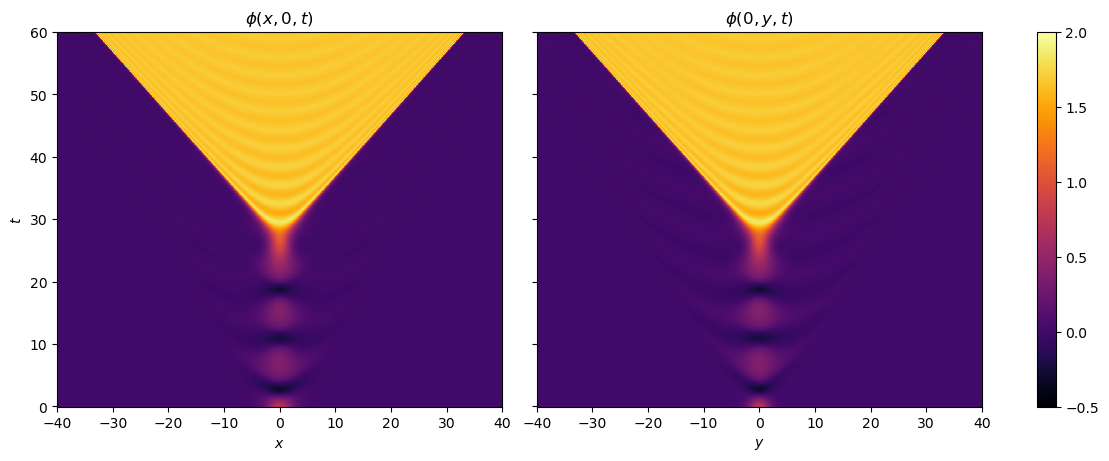

In [6]:
# -------------------------
# solução 2D
# -------------------------

nt = int(round(T/dt))
c1, c2 = rk4(phi0.copy(), pi0.copy(), dx, dt, nt, nsave, g2, g3)
t = dt*nsave*np.arange(c1.shape[0])

xx = np.concatenate([-x[:0:-1], x])
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True, constrained_layout=True)
for a, c, lab, tit in [(ax[0], c1, r"$x$", r"$\phi(x,0,t)$"), (ax[1], c2, r"$y$", r"$\phi(0,y,t)$")]:
    im = a.pcolormesh(xx, t, np.hstack([c[:, :0:-1], c]), cmap="inferno", vmin=-0.5, vmax=2.0,
                      shading="nearest", rasterized=True)
    a.set_xlabel(lab); a.set_title(tit)
ax[0].set_ylabel(r"$t$")
fig.colorbar(im, ax=ax)
plt.show()